# Pricing and Delta Hedging a GBP/USD Option Through the September 2022 Mini-Budget

## Background
In September 2022 I'd just started sixth form and watched sterling fall sharply after the UK mini-budget, without understanding what was happening in markets. Having since learned the basics of options and hedging, I wanted to go back to that episode.

## Question 
How effective is delta hedging for a GBP/USD option during a period of extreme exchange-rate volatility?

In this project, we approach this by pricing a one-month GBP put with Garman–Kohlhagen (the FX equivalent to Black-Scholes). Then, we delta-hedge it daily through September 2022, and compare the actual hedging error with Monte Carlo simulations of the same strategy, giving us a model-based benchmark for comparison.

## Data

First, we pull the required data for the project. The analysis uses three daily series from **July to October 2022** to cover the period before, during and after the mini-budget:

- `DEXUSUK` - GBP/USD spot exchange rate from FRED. This is the value of £1 in US dollars, recorded at noon in New York each trading day.
- `DFF` - US effective federal funds rate from FRED. This is the actual overnight interest rate at which US banks lend reserve balances to one another.
- `IUDBEDR` - UK Bank Rate from the Bank of England. This is the UK's main policy interest rate. It only changed twice in this window, so it is entered by hand from the decision dates (4 August and 22 September 2022).

All series are aligned to GBP/USD trading days. July and August provide enough history to calculate the 21-day volatility estimate at the start of September. We now import the relevant libraries for the project and pull the series data. In the following table, the spot exchange rate is denoted as $S$, the US interest rate as $r_d$ (domestic) and the UK interest rate as $r_f$ (foreign), with both rates expressed as decimals. A plot of GBP/USD against the time frame of July-October 2022 is also plotted below. 

In [1]:
import io, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

In [2]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}&cosd=2022-07-01&coed=2022-10-31" # template URL for FRED data

spot = pd.read_csv(url.format("DEXUSUK"), index_col=0, parse_dates=True, na_values=".").dropna() # request GBP/USD data 
effr = pd.read_csv(url.format("DFF"), index_col=0, parse_dates=True) # request USD interest rate data 

df = spot.rename(columns={"DEXUSUK": "S"}) # rename DEXUSUK to S
df["r_usd"] = effr["DFF"].reindex(df.index) / 100 # match USD-rate data to dates in df and convert to decimal

# bank rate: 1.25% until 3/8, 1.75% from 4/8, 2.25% from 22/9
df["r_gbp"] = 0.0125
df.loc["2022-08-04":, "r_gbp"] = 0.0175
df.loc["2022-09-22":, "r_gbp"] = 0.0225 # manually set GBP interest rate 

df 

,S,r_usd,r_gbp
observation_date,,,
2022-07-01,1.2048,0.0158,0.0125
2022-07-05,1.1932,0.0158,0.0125
2022-07-06,1.1907,0.0158,0.0125
2022-07-07,1.1994,0.0158,0.0125
2022-07-08,1.2036,0.0158,0.0125
...,...,...,...
2022-10-25,1.1469,0.0308,0.0225
2022-10-26,1.1615,0.0308,0.0225
2022-10-27,1.1574,0.0308,0.0225


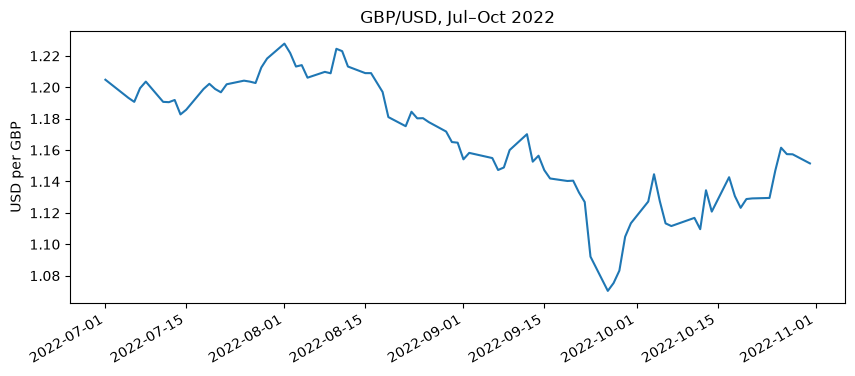

In [3]:
df["S"].plot(figsize=(10, 4), title="GBP/USD, Jul–Oct 2022", ylabel="USD per GBP", xlabel="") # plot spot rate data
plt.show()

From the plot, GBP/USD declined from around 1.22 in August to 1.14 in early September. Following the mini-budget, the exchange rate fell sharply to around 1.07 before slowly recovering to 1.13 by early October. The option studied in this project runs from 1 September to 3 October, capturing the full episode: the initial decline, the mini-budget shock, and the subsequent recovery. We now cover the options pricing models used in this project: Black-Scholes and Garman-Kohlhagen.

## Black–Scholes and Garman–Kohlhagen

Options are priced using Black–Scholes, adapted to FX through the Garman–Kohlhagen model. We first recap Black–Scholes, then show the change needed for currencies.

### Black–Scholes Model

Black–Scholes prices a European option on a non-dividend-paying stock, with these main assumptions:

- The stock price follows a geometric Brownian motion with constant volatility $\sigma$ and a constant risk-free rate $r$.
- The option can be replicated through continuous trading of the stock and risk-free asset.
- No transactional costs and no arbitrage (no risk-free opportunities to make money).

With spot $S$, strike $K$ and time to expiry $T$ in years:

$$
C = S\,N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S\,N(-d_1)
$$

$$
d_1 = \frac{\ln(S/K) + \left(r + \tfrac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$

where:
- $C$ and $P$ are the call and put prices
- $d_1$ - a standardised measure (z-score) of the option's position relative to the strike, incorporating time, volatility and rates.
- $d_2$ - another z-score, shifted from $d_1$ by $\sigma\sqrt{T}$.
- $N(\cdot)$ is the standard normal CDF.

#### Standard Normal in Black-Scholes
 
- $N(d_1)$ is how much the call price moves when the stock moves by £1. This is also known as the call's delta ($\Delta$). 
- Likewise, the put delta is denoted as $-N(-d_1)$, where the magnitude of the put delta is $N(-d_1)$: how much the put price moves but in opposite direction to the stock. 
- Both $N(d_1)$ and $N(-d_1)$ are always between 0 and 1. For the call delta, if the stock is far above K, you're deep in the money so the call moves pound-for-pound with the stock ($\Delta \approx 1$). If the stock is far below K, the reverse occurs and now $\Delta \approx 0$. If the stock is near K, $\Delta \approx 0.5$. The reverse logic applies for the put delta $-N(-d_1)$, which is between -1 and 0 instead. 
- $N(d_2)$ is more straightforward - simply the risk-neutral chance that the call ends in the money (the stock finishes above K). Likewise, $N(-d_2)$ is the chance the put ends in the money, (the stock finishes below K). The two add to 1, because the stock ends up either above or below K.

Black–Scholes assumes a single risk-free rate $r$. In FX, both currencies have their own interest rates, so the model needs to account for the differential between them. Garman–Kohlhagen extends Black–Scholes to do exactly this.

### Garman–Kohlhagen Model

Holding a foreign currency earns that currency's interest rate, in the same way that holding a stock earns a dividend yield. So an FX option depends on two rates:

- $r_d$: the domestic rate (here USD, since GBP/USD is quoted in USD per GBP)
- $r_f$: the foreign rate (here GBP)

The prices of a call and a put (GBP/USD) are:

$$
C = S e^{-r_f T} N(d_1) - K e^{-r_d T} N(d_2)
$$

$$
P = K e^{-r_d T} N(-d_2) - S e^{-r_f T} N(-d_1)
$$

$$
d_1 = \frac{\ln(S/K) + \left(r_d - r_f + \tfrac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$

Setting $r_f = 0$ recovers Black–Scholes.

The option studied here is a GBP put, which is the protection a UK importer needs if they are paying with dollars in the near future. The GBP put pays off if GBP falls beyond the strike, offsetting the extra cost required.  

We now implement the Garman- Kohlhagen formulas as a function that returns the price of a call or put. To check the implementation, we price both with the same inputs and test put–call parity: the left-hand side $C - P$ should equal the right-hand side $S e^{-r_f T} - K e^{-r_d T}$ exactly. The inputs are illustrative values close to GBP/USD at the start of September 2022. As we can see, both sides of put–call parity match, so the pricer is consistent.

In [4]:
def gk_price(S, K, T, r_d, r_f, sigma, kind="put"):
    d1 = (np.log(S / K) + (r_d - r_f + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    if kind == "call":
        return S * np.exp(-r_f * T) * norm.cdf(d1) - K * np.exp(-r_d * T) * norm.cdf(d2)
    return K * np.exp(-r_d * T) * norm.cdf(-d2) - S * np.exp(-r_f * T) * norm.cdf(-d1)

# Put–call parity check
S, K, T, r_d, r_f, sigma = 1.16, 1.16, 1/12, 0.0233, 0.0175, 0.10

C = gk_price(S, K, T, r_d, r_f, sigma, "call")
P = gk_price(S, K, T, r_d, r_f, sigma, "put")

print(C - P, S * np.exp(-r_f * T) - K * np.exp(-r_d * T))

0.0005597143484861178 0.0005597143484861178


We now have the option price which tells us its value, but we also want to know how that value changes when the underlying inputs change. We now look at the Greeks which measure these sensitivities.

## Greeks

The Greeks measure how the option's price responds to changes in its inputs. Suppose the option price is a function of it's inputs: 

$$
V=V(S,σ,r,T,…)
$$

Then the Greeks are essentially partial derivatives of the option price - changing one input whilst keeping the rest fixed. 

For the GBP put, with $n(\cdot)$ the standard normal PDF:

- Delta: change in price per unit change in spot (partial derivative w.r.t. spot)

$$
\Delta = \frac{\partial V}{\partial S} = -e^{-r_f T} N(-d_1)
$$

- Gamma: the second partial derivative with respect to spot. (second partial derivative w.r.t. spot)

$$
\Gamma = \frac{\partial^2 V}{\partial S^2} = \frac{e^{-r_f T} n(d_1)}{S \sigma \sqrt{T}}
$$

- Vega: change in price per unit change in volatility (partial derivative wr.t. volatility)

$$
\nu = \frac{\partial V}{\partial \sigma} = S e^{-r_f T} n(d_1) \sqrt{T}
$$

- Theta: the change in price as time passes (partial derivative w.r.t. time passing). 

$$
\Theta = -\frac{\partial V}{\partial T} = -\frac{S e^{-r_f T} n(d_1) \sigma}{2\sqrt{T}} - r_f S e^{-r_f T} N(-d_1) + r_d K e^{-r_d T} N(-d_2)
$$

Delta drives the hedge: the seller holds $\Delta$ units of GBP against the option. Gamma determines how quickly that hedge goes out of date as spot moves.

To check the formulas, each Greek is compared with a finite-difference estimate: nudge one input slightly, reprice, and measure the change.

In [5]:
def gk_put_greeks(S, K, T, r_d, r_f, sigma):
    d1 = (np.log(S / K) + (r_d - r_f + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    delta = -np.exp(-r_f * T) * norm.cdf(-d1)
    gamma = np.exp(-r_f * T) * norm.pdf(d1) / (S * sigma * np.sqrt(T))
    vega  = S * np.exp(-r_f * T) * norm.pdf(d1) * np.sqrt(T)
    theta = (-S * np.exp(-r_f * T) * norm.pdf(d1) * sigma / (2 * np.sqrt(T))
             - r_f * S * np.exp(-r_f * T) * norm.cdf(-d1)
             + r_d * K * np.exp(-r_d * T) * norm.cdf(-d2))
    return delta, gamma, vega, theta


# Finite-difference check: nudge one input, reprice, measure the change
h = 1e-4
fd_delta = (gk_price(S+h, K, T, r_d, r_f, sigma) - gk_price(S-h, K, T, r_d, r_f, sigma)) / (2*h)
fd_gamma = (gk_price(S+h, K, T, r_d, r_f, sigma) - 2*gk_price(S, K, T, r_d, r_f, sigma) + gk_price(S-h, K, T, r_d, r_f, sigma)) / h**2
fd_vega  = (gk_price(S, K, T, r_d, r_f, sigma+h) - gk_price(S, K, T, r_d, r_f, sigma-h)) / (2*h)
fd_theta = -(gk_price(S, K, T+h, r_d, r_f, sigma) - gk_price(S, K, T-h, r_d, r_f, sigma)) / (2*h)

print("Analytical: ", np.round(gk_put_greeks(S, K, T, r_d, r_f, sigma), 6))
print("Finite diff:", np.round((fd_delta, fd_gamma, fd_vega, fd_theta), 6))

Analytical:  [-0.486854 11.89045   0.133332 -0.076419]
Finite diff: [-0.486854 11.890441  0.133332 -0.076419]


## The Trade

We now set up the option that the rest of the project follows. On the first trading day of September 2022, a UK importer that owes $10m in one month buys a GBP put / USD call from a bank, which sells it and delta-hedges it. 

The terms are fixed by simple rules rather than chosen with hindsight:

- Dates: inception on 1 September 2022, expiry on 3 October 2022 (the first trading days of each month)
- Volatility: $\sigma$ is the annualised standard deviation of the 21 daily log returns up to inception, held fixed for the option's life
- Strike: at-the-money forward, $K = F = S_0 e^{(r_d - r_f)T}$
- Notional: sized to cover \$10m, so the GBP notional is $N = 10{,}000{,}000 / K$
- Time: measured in trading days, $T = \text{number of trading days} / 252$

With an ATM-forward strike, put–call parity gives $C = P$, a useful check that the setup is right.

In [6]:
t0, tT = "2022-09-01", "2022-10-03"           # inception and expiry
trade = df.loc[t0:tT]                         # the option's life

S0 = trade["S"].iloc[0]
r_d = trade["r_usd"].iloc[0]
r_f = trade["r_gbp"].iloc[0]
T = (len(trade) - 1) / 252                    # trading days to expiry, in years

log_ret = np.log(df["S"]).diff()
sigma = log_ret.loc[:t0].tail(21).std() * np.sqrt(252)

K = S0 * np.exp((r_d - r_f) * T)              # ATM-forward strike
N = 10_000_000 / K                            # GBP notional

P0 = gk_price(S0, K, T, r_d, r_f, sigma, "put")
C0 = gk_price(S0, K, T, r_d, r_f, sigma, "call")
premium_usd = N * P0

print(f"S0 = {S0:.4f}, K = {K:.4f}, sigma = {sigma:.2%}, T = {T:.4f}")
print(f"Put = {P0:.5f}, Call = {C0:.5f} USD per GBP")
print(f"Premium = ${premium_usd:,.0f} (£{premium_usd / S0:,.0f})")

S0 = 1.1541, K = 1.1547, sigma = 9.08%, T = 0.0833
Put = 0.01205, Call = 0.01205 USD per GBP
Premium = $104,318 (£90,389)


At inception, spot is 1.1541 and the ATM-forward strike is 1.1547. The 21-day historical volatility is 9.08%, reflecting a relatively calm August, and this is the volatility the option is priced and hedged with for its whole life. The put and call prices are equal, as put–call parity requires for an ATM-forward strike. The premium is \$104,318 (about £90,400), roughly 1% of the \$10m notional.

## Delta Hedge

Now the bank sold the put, so it loses money if sterling falls. To offset this, it holds $\Delta$ units of GBP per unit of notional. Since the put's delta is negative, this means a short sterling position that gains as sterling falls. Small moves in spot then roughly cancel between the option and the hedge.

Under the model's assumptions, rebalancing continuously would replicate the option exactly: the premium received would be precisely enough to cover the payoff. In practice the hedge is rebalanced once a day, so between rebalances the hedge goes out of date. How much it drifts depends on gamma and on the size of each day's move. The leftover gain or loss at expiry is the hedging error.

The hedge works as follows:

1. Inception: receive the premium in USD, and sell $|N\Delta|$ GBP at spot. The proceeds go into a USD cash account.
2. Daily: the USD cash earns $r_d$ and the GBP position accrues $r_f$. Then recompute delta with the new spot and one day less to expiry, and trade GBP to match it.
3. Expiry: close the GBP position and pay the put's payoff, $N \max(K - S_T, 0)$.

The cash left over is the hedging error in USD. A perfect hedge would leave exactly zero. Volatility and interest rates are held at their inception values throughout, as the model assumes.

The same function is used for both simulated and real spot paths, so the two are compared on identical terms.

In [7]:
def delta_hedge(path, K, r_d, r_f, sigma, N):
    dt = 1 / 252
    n = len(path) - 1                                   # number of trading days

    # Inception: receive premium, set up the hedge
    delta = gk_put_greeks(path[0], K, n*dt, r_d, r_f, sigma)[0]
    hedge = N * delta                                   # GBP held (negative = short)
    cash = N * gk_price(path[0], K, n*dt, r_d, r_f, sigma) - hedge * path[0]

    # Each day: accrue interest, then rebalance
    for i in range(1, n + 1):
        cash *= np.exp(r_d * dt)
        hedge *= np.exp(r_f * dt)
        if i < n:
            new_hedge = N * gk_put_greeks(path[i], K, (n-i)*dt, r_d, r_f, sigma)[0]
            cash -= (new_hedge - hedge) * path[i]       # buy/sell GBP at today's spot
            hedge = new_hedge

    # Expiry: close the hedge, pay the option
    cash += hedge * path[-1]
    cash -= N * max(K - path[-1], 0)
    return cash                                          # hedging error in USD

## Monte Carlo Baseline

Before testing the hedge on the real September path, we need to know what a "normal" hedging error looks like. To find out, we simulate spot paths where the model's assumptions hold exactly: GBP/USD follows geometric Brownian motion with the same volatility the option was priced with,

$$
S_{t+\Delta t} = S_t \exp\left(\left(r_d - r_f - \tfrac{1}{2}\sigma^2\right)\Delta t + \sigma\sqrt{\Delta t}\,Z\right), \qquad Z \sim N(0,1)
$$

with $\Delta t = 1/252$. Each simulated path starts at $S_0$ and runs for the same 21 trading days as the real option, and the same delta hedge is run on each.

Because the model is correct on these paths, the hedging error should average close to zero. Any spread around zero comes only from rebalancing daily rather than continuously. This distribution is the baseline the real September result is compared against.

In [8]:
n_paths = 5000
n_days = len(trade) - 1
dt = 1 / 252
rng = np.random.default_rng(42)                     # fixed seed, reproducible

Z = rng.standard_normal((n_paths, n_days))
log_steps = (r_d - r_f - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
paths = S0 * np.exp(np.cumsum(log_steps, axis=1))
paths = np.column_stack([np.full(n_paths, S0), paths])   # add S0 at the start

mc_errors = np.array([delta_hedge(p, K, r_d, r_f, sigma, N) for p in paths])

print(f"Mean hedging error: ${mc_errors.mean():,.0f}")
print(f"Std of hedging error: ${mc_errors.std():,.0f}")

Mean hedging error: $-507
Std of hedging error: $19,837


The mean hedging error is close to zero (−\$507, within simulation noise), confirming the hedge is implemented correctly: when the model's assumptions hold, the premium covers the cost of hedging on average. The standard deviation of about \$19,800, roughly 19% of the premium, is the error that comes purely from rebalancing daily rather than continuously. This is the baseline: a hedging error within about ±\$40,000 (two standard deviations) is what the model itself would consider normal. We also add a plot of the simulations:    

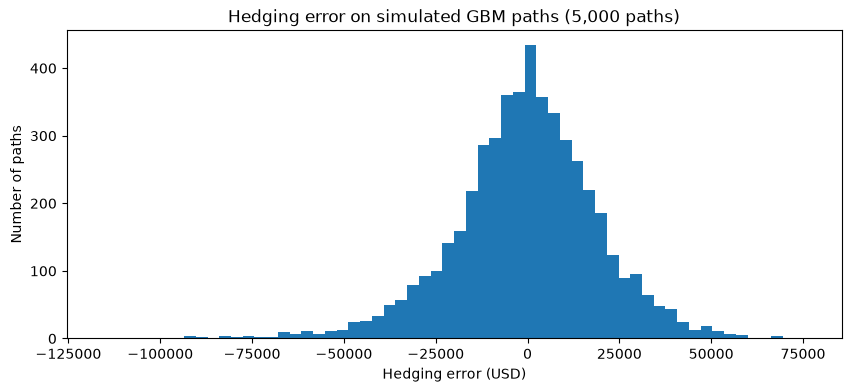

In [9]:
plt.figure(figsize=(10, 4))
plt.hist(mc_errors, bins=60)
plt.title("Hedging error on simulated GBM paths (5,000 paths)")
plt.xlabel("Hedging error (USD)")
plt.ylabel("Number of paths")
plt.show()

The distribution is centred on zero but has a longer left tail. This is because the bank is short gamma: on calm paths it earns the time decay it was paid for and makes a small gain, but on paths with large moves the daily hedge falls behind and losses can be much bigger. Large spot moves are therefore the main risk to the hedge, even when the model is correct.

## Option Through the Shock

We now follow the option along the real GBP/USD path from 1 September to expiry. Each day, the put is revalued and its Greeks recomputed using that day's spot and the remaining time to expiry, with volatility and rates held at their inception values.

This shows what the bank was dealing with: as spot falls below the strike, the put moves into the money, its value rises, and its delta moves towards $-1$. Gamma, which measures how fast the hedge goes out of date, depends on how close spot is to the strike and how little time is left.

We also compare the volatility the option was priced with to the volatility GBP/USD actually showed over the option's life.

Priced with: 9.08%   Realised over option's life: 18.35%


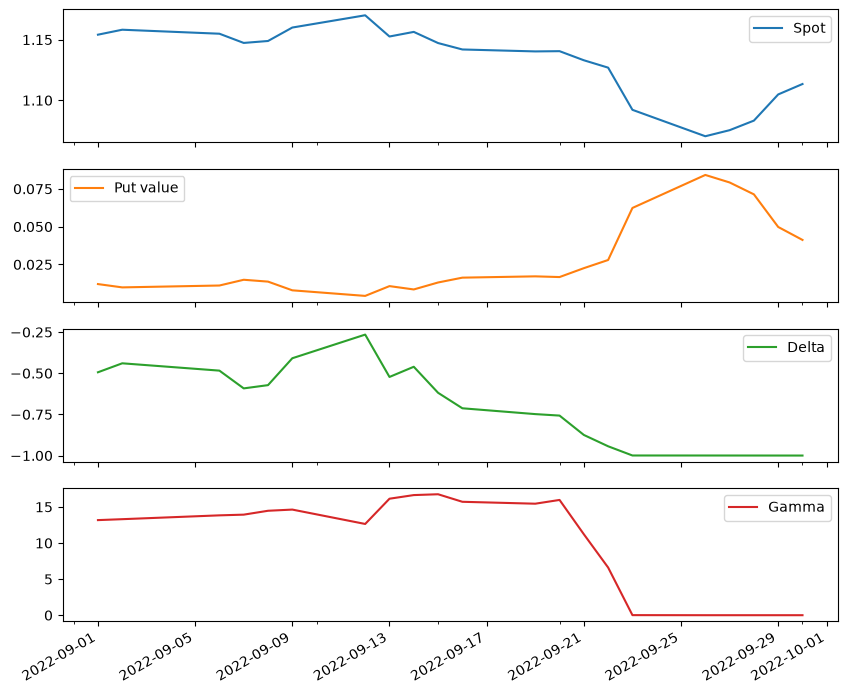

In [10]:
rows = []
for i in range(n_days):                        # every day except expiry
    S = trade["S"].iloc[i]
    T_left = (n_days - i) / 252
    delta, gamma, vega, theta = gk_put_greeks(S, K, T_left, r_d, r_f, sigma)
    rows.append([S, gk_price(S, K, T_left, r_d, r_f, sigma), delta, gamma])

path = pd.DataFrame(rows, index=trade.index[:-1], columns=["Spot", "Put value", "Delta", "Gamma"])

realised_vol = log_ret.loc[t0:tT].iloc[1:].std() * np.sqrt(252)
print(f"Priced with: {sigma:.2%}   Realised over option's life: {realised_vol:.2%}")

path.plot(subplots=True, figsize=(10, 9), xlabel="")
plt.show()

The option was priced with 9.08% volatility, but GBP/USD's realised volatility over the option's life was 18.35%, roughly double.

For the first three weeks, spot stayed close to the strike, so the put's delta moved around between −0.25 and −0.75 and gamma was high: the period where the daily hedge goes out of date fastest. Between 21 and 23 September, spot fell through 1.13 to 1.09, the put moved deep into the money, delta reached −1 and gamma collapsed to zero.

The sharpest moves of the crisis, the low of about 1.07 and the rebound to 1.11, therefore happened after gamma had already disappeared. By then the hedge was effectively a full short sterling position that moved one-for-one with the option. This suggests the hedge was most exposed in the days before the shock, not during it.

## Hedging the Real Path

We now run the same delta hedge on the actual GBP/USD path from 1 September to 3 October 2022. Everything else is identical to the simulations: same strike, volatility, rates, notional and daily rebalancing. The only difference is the spot path.

To judge the result, we compare it with the Monte Carlo baseline: how many standard deviations it sits from the simulated mean, and what share of simulated paths did worse.

In [11]:
real_error = delta_hedge(trade["S"].values, K, r_d, r_f, sigma, N)

z = (real_error - mc_errors.mean()) / mc_errors.std()
pct_worse = (mc_errors < real_error).mean()

print(f"Real hedging error: ${real_error:,.0f} ({real_error / premium_usd:.0%} of premium)")
print(f"Standard deviations from baseline mean: {z:.2f}")
print(f"Share of simulated paths that did worse: {pct_worse:.1%}")

Real hedging error: $-29,292 (-28% of premium)
Standard deviations from baseline mean: -1.45
Share of simulated paths that did worse: 7.1%


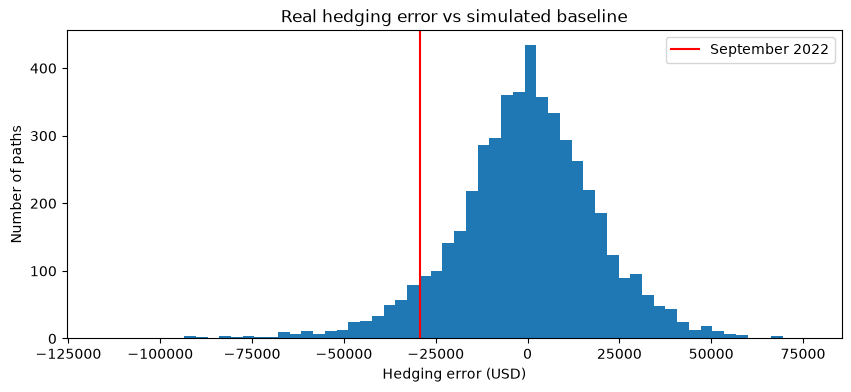

In [15]:
plt.figure(figsize=(10, 4))
plt.hist(mc_errors, bins=60)
plt.axvline(real_error, color="red", label="September 2022")
plt.title("Real hedging error vs simulated baseline")
plt.xlabel("Hedging error (USD)")
plt.ylabel("Number of paths")
plt.legend()
plt.savefig("hedging_error_vs_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

On the real path, the delta hedge lost about \$29,300, around 28% of the premium. The premium the bank received did not fully cover the cost of hedging.

Against the Monte Carlo baseline, however, the result is not extreme: it sits 1.45 standard deviations below the mean, and around 7% of simulated paths did worse. This is despite realised volatility being roughly double the volatility the option was priced with.

The previous section explains why. The largest moves of the crisis came after the put had moved deep into the money and its gamma had collapsed, so the hedge was already moving almost one-for-one with the option. The losses came mainly from the high-gamma period before the shock, not from the shock itself.

## Break-even Volatility

The option was priced with 9.08% volatility and lost money. A natural question is: what volatility would the bank have needed to price and hedge with to exactly break even on this path?

Changing $\sigma$ changes both the premium received and every daily delta, so the whole hedge is rerun for each candidate volatility. The break-even volatility $\sigma_{BE}$ is the value at which the hedging error is zero:

$$
\text{Hedging error}(\sigma_{BE}) = 0
$$

This is found numerically with Brent's method, a root-finding algorithm that searches between a lower and an upper bound. Comparing $\sigma_{BE}$ with the priced volatility (9.08%) and the realised volatility (18.35%) shows how much the hedge's losses depended on *when* the large moves happened.

In [13]:
hedge_error = lambda s: delta_hedge(trade["S"].values, K, r_d, r_f, s, N)

sigma_be = brentq(hedge_error, 0.01, 0.60)

print(f"Priced vol:     {sigma:.2%}")
print(f"Break-even vol: {sigma_be:.2%}")
print(f"Realised vol:   {realised_vol:.2%}")

Priced vol:     9.08%
Break-even vol: 14.55%
Realised vol:   18.35%


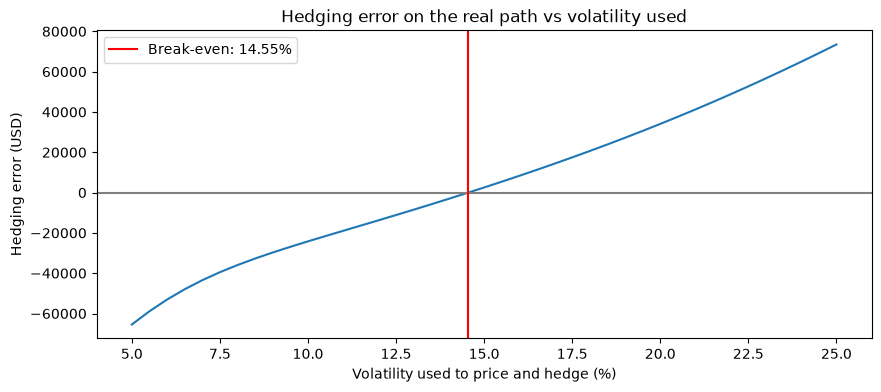

In [14]:
vols = np.linspace(0.05, 0.25, 41)
errors = [hedge_error(s) for s in vols]

plt.figure(figsize=(10, 4))
plt.plot(vols * 100, errors)
plt.axhline(0, color="grey")
plt.axvline(sigma_be * 100, color="red", label=f"Break-even: {sigma_be:.2%}")
plt.title("Hedging error on the real path vs volatility used")
plt.xlabel("Volatility used to price and hedge (%)")
plt.ylabel("Hedging error (USD)")
plt.legend()
plt.show()

The break-even volatility is 14.55%. The bank priced the option at 9.08%, so it would have needed to charge roughly 60% more volatility to cover the cost of hedging. However, break-even volatility is well below the 18.35% that GBP/USD actually realised.

The gap exists because the hedge only loses money from moves that happen while gamma is high. Much of September's volatility came from the crash and rebound after 23 September, when the put was deep in the money and its gamma was close to zero. That volatility counts towards realised volatility but cost the hedge very little. What mattered for the bank was not how volatile the month was, but when the volatility arrived.

The curve crosses zero exactly once, confirming that the break-even volatility is unique.